# TP2 – Exercice 2 : Choix d'un backbone pour un déploiement embarqué
**M2 SDIA – Advanced Artificial Intelligence – ENSET**

**Noms : Wijdane AARROUB**

Jeu de données de ce notebook : **flower_photos (224×224)**. Exécution sur *Google Colab, GPU activé*.
`QUICK = True` pour un test rapide du code, puis `False` pour les vrais résultats. Les figures vont dans `figures/`, les chiffres dans `RESULTS` (exportés en `results_ex2.json`).

In [1]:
import os, time, pathlib, json
from sklearn.model_selection import train_test_split
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

QUICK = False            # True = vérification rapide du code
SEED = 42
EP = 2 if QUICK else 10  # époques par phase (consigne du TP)
EP_SCRATCH = 2 if QUICK else 20  # le CNN from scratch converge plus lentement
keras.utils.set_random_seed(SEED)
os.makedirs("figures", exist_ok=True)
RESULTS = {}
print("TF", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

def count_params(m):
    tr = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    nt = int(sum(np.prod(w.shape) for w in m.non_trainable_weights))
    return tr, nt

def plot_curves(hists, title, split=None, fname=None):
    """Courbes accuracy/loss concaténées sur plusieurs phases d'entraînement."""
    h = {k: sum([x.history[k] for x in hists], []) for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
    ep = np.arange(1, len(h["accuracy"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (k1, k2, t) in zip(ax, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
        a.plot(ep, h[k1], label="train"); a.plot(ep, h[k2], label="validation")
        if split: a.axvline(split + 0.5, ls="--", c="gray", label="début fine-tuning")
        a.set_xlabel("époque"); a.set_title(f"{title} – {t}"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=150)
    plt.show()

TF 2.21.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 0. Données (flower_photos)

In [2]:
import pathlib
import shutil
import tarfile
import tensorflow as tf

tgz_path = pathlib.Path('/content/data/flower_photos.tgz')
data_dir = pathlib.Path('/content/data/flower_photos')

# Supprimer le fichier d'archive corrompu s'il existe et est trop petit
if tgz_path.exists() and tgz_path.stat().st_size < 200000000:
    print("Archive corrompue ou incomplète détectée. Suppression...")
    tgz_path.unlink()

# Téléchargement d'une nouvelle archive valide
if not tgz_path.exists():
    print("Téléchargement d'une nouvelle archive complète...")
    url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
    pathlib.Path('/content/data').mkdir(parents=True, exist_ok=True)
    # keras get_file va télécharger l'archive vers /content/data/flower_photos.tgz
    tf.keras.utils.get_file(str(tgz_path.name), origin=url, extract=False, cache_dir='/content', cache_subdir='data')

# Suppression de l'ancienne extraction partielle et ré-extraction propre
if data_dir.exists():
    shutil.rmtree(data_dir)

print("Extraction propre de l'archive...")
with tarfile.open(tgz_path, "r:gz") as tar:
    tar.extractall(path='/content/data')

# Configuration de l'accès au répertoire
if not data_dir.exists():
    data_dir = pathlib.Path('/content/data')

if (data_dir / 'flower_photos').exists():
    data_dir = data_dir / 'flower_photos'

class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
print("Classes trouvées :", class_names)

def to_numpy(ds):
    """Matérialise un dataset en tableaux (uint8)."""
    xs, ys = [], []
    for x, y in ds:
        xs.append(x.numpy().astype("uint8"))
        ys.append(y.numpy())
    return np.concatenate(xs), np.concatenate(ys)

Archive corrompue ou incomplète détectée. Suppression...
Téléchargement d'une nouvelle archive complète...
228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Extraction propre de l'archive...


/tmp/ipykernel_1276/3766377363.py:28: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path='/content/data')


Classes trouvées : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


# Exercice 2 – Choix d'un backbone pour un déploiement embarqué
## 1-2. Extraction unique des caractéristiques (224×224) et tête de classification

In [3]:
# ============================================================
# Ex.2 – Q1/Q2/Q3 : extraction unique des caractéristiques + têtes de classification
# ============================================================
IMG2 = 224
# Même découpage (seed=42, 80/20) que l'Exercice 1 ; taille d'entrée 224x224 imposée par l'énoncé
tr2 = tf.keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset="training", seed=42,
                                                  image_size=(IMG2, IMG2), batch_size=32)
va2 = tf.keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset="validation", seed=42,
                                                  image_size=(IMG2, IMG2), batch_size=32)
X2_tr, y2_tr = to_numpy(tr2); X2_va, y2_va = to_numpy(va2)
print(X2_tr.shape, X2_va.shape)

from tensorflow.keras.applications import vgg16, resnet50, mobilenet_v2, efficientnet
# Pour chaque tronc : (constructeur, preprocess_input PROPRE au modèle).
# include_top=False retire la tête ImageNet ; pooling="avg" donne un vecteur par image.
# NB : VGG16/ResNet50 -> "caffe" (BGR, centrage), MobileNetV2 -> [-1,1], EfficientNet -> identité (rescaling intégré).
BACKBONES = {
    "VGG16":          (lambda: vgg16.VGG16(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3)), vgg16.preprocess_input),
    "ResNet50":       (lambda: resnet50.ResNet50(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3)), resnet50.preprocess_input),
    "MobileNetV2":    (lambda: mobilenet_v2.MobileNetV2(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3)), mobilenet_v2.preprocess_input),
    "EfficientNetB0": (lambda: efficientnet.EfficientNetB0(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3)), efficientnet.preprocess_input),
}

def extract(model, pre, X, bs=64):
    """Passe avant unique par lot : renvoie la matrice (N, dim_features)."""
    out = []
    for i in range(0, len(X), bs):
        out.append(model.predict(pre(X[i:i + bs].astype("float32")), verbose=0))
    return np.concatenate(out)

def latency_ms(model, pre, n=100, repeats=3, device=None):
    """Latence moyenne par image (batch = 1), en ms.
    Corrections par rapport à la 1re version : (i) graphe compilé via tf.function
    (on mesure le réseau, pas le surcoût Python/eager), (ii) 20 appels de warm-up
    (traçage + initialisation GPU), (iii) médiane sur plusieurs répétitions."""
    ctx = tf.device(device) if device else tf.device(None)
    with ctx:
        xs = [tf.constant(pre(X2_va[i:i + 1].astype("float32"))) for i in range(n)]
        infer = tf.function(lambda x: model(x, training=False))
        for x in xs[:20]: infer(x).numpy()                       # warm-up
        times = []
        for _ in range(repeats):
            t = time.perf_counter()
            for x in xs: infer(x).numpy()                        # .numpy() force la synchro GPU
            times.append((time.perf_counter() - t) / n * 1000)
    return float(np.median(times))

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def dense_head(Ftr, ytr, Fva, yva, epochs=30):
    """2e option du sujet : tête Dense Softmax (Keras) entraînée sur les vecteurs extraits."""
    sc = StandardScaler().fit(Ftr)
    h = keras.Sequential([keras.Input((Ftr.shape[1],)), layers.Dropout(0.2), layers.Dense(5, activation="softmax")])
    h.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h.fit(sc.transform(Ftr), ytr, epochs=epochs, batch_size=32, verbose=0)
    return h.evaluate(sc.transform(Fva), yva, verbose=0)[1]

FEATS, PRED, rows = {}, {}, []
for name, (ctor, pre) in BACKBONES.items():
    print("→", name)
    keras.backend.clear_session()                                # état propre -> mesures de latence comparables
    m = ctor()
    t0 = time.time(); Ftr, Fva = extract(m, pre, X2_tr), extract(m, pre, X2_va); t_ext = time.time() - t0
    FEATS[name] = (Ftr, Fva)
    # Tête 1 : régression logistique (sklearn) sur caractéristiques standardisées
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    clf.fit(Ftr, y2_tr); acc = clf.score(Fva, y2_va); PRED[name] = clf.predict(Fva)
    # Tête 2 : Dense Softmax (Keras)
    acc_d = dense_head(Ftr, y2_tr, Fva, y2_va)
    # Incertitude binomiale à 95 % de l'accuracy (n = taille de la validation)
    ic = 1.96 * np.sqrt(acc * (1 - acc) / len(y2_va))
    # Latences : GPU (défaut) et CPU (proxy smartphone) avec le même protocole
    lat_gpu = latency_ms(m, pre)
    with tf.device("/CPU:0"):
        m_cpu = ctor()                                           # copie dont les poids vivent sur CPU
    lat_cpu = latency_ms(m_cpu, pre, n=30, device="/CPU:0")
    m.save(f"{name}.keras"); size = os.path.getsize(f"{name}.keras") / 1e6
    rows.append({"Modèle": name, "Params tronc (M)": m.count_params() / 1e6, "Dim. features": Ftr.shape[1],
                 "Acc. LogReg (%)": 100 * acc, "± IC95 (pts)": 100 * ic, "Acc. Dense (%)": 100 * acc_d,
                 "Latence GPU (ms/img)": lat_gpu, "Latence CPU (ms/img)": lat_cpu,
                 "Taille (Mo)": size, "Extraction (s)": t_ext})
    print(rows[-1])
df_bb = pd.DataFrame(rows).round(2); df_bb.to_csv("figures/ex2_backbones.csv", index=False)
RESULTS["backbones"] = df_bb.to_dict("records")
df_bb


Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
(2936, 224, 224, 3) (734, 224, 224, 3)
→ VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
{'Modèle': 'VGG16', 'Params tronc (M)': 14.714688, 'Dim. features': 512, 'Acc. LogReg (%)': 85.42234332425068, '± IC95 (pts)': np.float64(2.55292255744325), 'Acc. Dense (%)': 89.1008198261261, 'Latence GPU (ms/img)': 13.079366570000275, 'Latence CPU (ms/img)': 273.2533847333343, 'Taille (Mo)': 58.933792, 'Extraction (s)': 33.905632734298706}
→ ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
{'Modèle': 'ResNet50', 'Params tronc (M)': 23.587712, 'Dim. features': 2048, 'Acc. LogReg (%)': 90.59945504087193, '± IC95 (pts)': np.float64(2.1112873690238083), 'Acc. Dense (%)': 91.00817441940308, 'Latence GPU (ms/img)': 10.308070160000398, 'Latence CPU (ms/img)': 108.0917104999988, 'Taille (Mo)': 94.993524, 'Extraction (s)': 33.39601922035217}
→

,Modèle,Params tronc (M),Dim. features,Acc. LogReg (%),± IC95 (pts),Acc. Dense (%),Latence GPU (ms/img),Latence CPU (ms/img),Taille (Mo),Extraction (s)
0,VGG16,14.71,512,85.42,2.55,89.10,13.08,273.25,58.93,33.91
1,ResNet50,23.59,2048,90.60,2.11,91.01,10.31,108.09,94.99,33.40
2,MobileNetV2,2.26,1280,89.65,2.20,89.10,5.63,29.80,9.60,29.26
3,EfficientNetB0,4.05,1280,91.83,1.98,92.51,8.40,52.03,17.03,41.85


**Lecture du tableau.**
- *Params tronc* : ne comptent que le tronc (`include_top=False`). Les 138 M de VGG16 cités dans l'énoncé incluent ses 3 couches denses (~124 M) ; le tronc convolutif seul fait 14,7 M. Idem pour MobileNetV2 (3,5 M avec tête ImageNet, 2,3 M sans) et EfficientNetB0 (5,3 M vs 4,05 M).
- *IC95* : avec 734 images de validation, l'accuracy est connue à ≈ ±2 points près. Des intervalles qui se chevauchent suggèrent, sans le prouver, l'absence de différence. Les modèles étant évalués sur les *mêmes* 734 images, le test approprié est le **McNemar exact** (apparié, plus puissant) : voir la cellule « Têtes linéaires réglées par validation croisée + McNemar » ci-dessous.
- *Latence CPU* : proxy d'un smartphone d'entrée de gamme (ordre de grandeur, pas une mesure sur appareil). La latence GPU est mesurée avec `tf.function` et un protocole identique pour les 4 modèles. D'une exécution à l'autre, les latences varient d'environ 10 % (ex. MobileNetV2 sur CPU : 28 puis 32 ms ; VGG16 : 254 puis 274 ms) mais **l'ordre des modèles reste identique**, ce qui est la conclusion qui compte pour le choix.

- *Deux têtes* : la régression logistique et la tête `Dense(5, softmax)` sont **toutes deux des classifieurs linéaires** (même capacité). Leur écart (0 à 4 pts ; VGG16 : 85,4 % → 89,1 %) vient donc de la **régularisation et de l'optimisation** — pénalité L2 par défaut (C = 1) pour la régression logistique, dropout et arrêt à 30 époques pour la tête Dense — et non d'une séparabilité différente. La cellule suivante règle C par validation croisée (sur le train seulement) pour comparer les troncs à régularisation équivalente.


### Têtes linéaires réglées par validation croisée + McNemar
Deux vérifications sans ré-extraction (les features sont en mémoire) : (1) régler la régularisation C de la régression logistique par CV 5 plis **sur le train uniquement** ; (2) comparer les modèles deux à deux avec un test de McNemar exact, valable pour des modèles évalués sur les mêmes images (seuil de Bonferroni 0,05/5 = 0,01).

In [4]:
# ============================================================
# Têtes linéaires réglées par validation croisée (sur le TRAIN uniquement) + tests appariés (McNemar exact)
# Les features sont déjà en mémoire (FEATS) : aucune ré-extraction n'est nécessaire.
# ============================================================
from sklearn.linear_model import LogisticRegressionCV
from scipy.stats import binomtest

rows_cv, PRED_CV = [], {}
for name in BACKBONES:
    Ftr, Fva = FEATS[name]
    clf_cv = make_pipeline(StandardScaler(),
                           LogisticRegressionCV(Cs=[1e-4, 1e-3, 1e-2, 1e-1, 1.0], cv=5, max_iter=3000))
    clf_cv.fit(Ftr, y2_tr)                                   # C choisi par CV 5 plis sur le train seulement
    PRED_CV[name] = clf_cv.predict(Fva)
    row = df_bb[df_bb["Modèle"] == name].iloc[0]
    rows_cv.append({"Modèle": name, "C optimal (CV)": float(np.ravel(clf_cv[-1].C_)[0]),
                    "Acc. LogReg C=1 (%)": row["Acc. LogReg (%)"],
                    "Acc. LogReg C optimal (%)": 100 * float(np.mean(PRED_CV[name] == y2_va)),
                    "Acc. Dense (%)": row["Acc. Dense (%)"]})
df_cv = pd.DataFrame(rows_cv).round(2); df_cv.to_csv("figures/ex2_logreg_cv.csv", index=False)
RESULTS["logreg_cv"] = df_cv.to_dict("records")
print(df_cv.to_string(index=False))

def mcnemar_exact(pa, pb, y):
    """Test de McNemar exact : mêmes images, on ne compte que les cas où un seul des deux modèles a raison."""
    a_ok, b_ok = pa == y, pb == y
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return b, c, (binomtest(b, b + c, 0.5).pvalue if b + c else 1.0)

pairs = [("EfficientNetB0", "MobileNetV2"), ("EfficientNetB0", "ResNet50"), ("ResNet50", "MobileNetV2"),
         ("MobileNetV2", "VGG16"), ("ResNet50", "VGG16")]
rows_mc = []
for head, P in [("LogReg C=1", PRED), ("LogReg C optimal", PRED_CV)]:
    for a, b in pairs:
        n_a, n_b, p = mcnemar_exact(P[a], P[b], y2_va)
        rows_mc.append({"Tête": head, "A vs B": f"{a} vs {b}", "A seul correct": n_a, "B seul correct": n_b,
                        "Δ acc. A−B (pts)": 100 * (np.mean(P[a] == y2_va) - np.mean(P[b] == y2_va)),
                        "p (McNemar exact)": p, "Signif. (Bonferroni, 5 tests)": p < 0.05 / len(pairs)})
df_mc = pd.DataFrame(rows_mc).round(4); df_mc.to_csv("figures/ex2_mcnemar.csv", index=False)
RESULTS["mcnemar"] = df_mc.astype(object).where(df_mc.notna(), None).to_dict("records")
df_mc


        Modèle  C optimal (CV)  Acc. LogReg C=1 (%)  Acc. LogReg C optimal (%)  Acc. Dense (%)
         VGG16            0.01                85.42                      88.01           89.10
      ResNet50            0.01                90.60                      91.83           91.01
   MobileNetV2            0.01                89.65                      90.33           89.10
EfficientNetB0            0.01                91.83                      92.92           92.51


,Tête,A vs B,A seul correct,B seul correct,Δ acc. A−B (pts),p (McNemar exact),"Signif. (Bonferroni, 5 tests)"
0,LogReg C=1,EfficientNetB0 vs MobileNetV2,43,27,2.1798,0.0722,False
1,LogReg C=1,EfficientNetB0 vs ResNet50,34,25,1.2262,0.2976,False
2,LogReg C=1,ResNet50 vs MobileNetV2,44,37,0.9537,0.5052,False
3,LogReg C=1,MobileNetV2 vs VGG16,67,36,4.2234,0.0029,True
4,LogReg C=1,ResNet50 vs VGG16,63,25,5.1771,0.0001,True
5,LogReg C optimal,EfficientNetB0 vs MobileNetV2,41,22,2.5886,0.0226,False
6,LogReg C optimal,EfficientNetB0 vs ResNet50,30,22,1.0899,0.3317,False
7,LogReg C optimal,ResNet50 vs MobileNetV2,37,26,1.4986,0.2074,False
8,LogReg C optimal,MobileNetV2 vs VGG16,50,33,2.3161,0.0784,False
9,LogReg C optimal,ResNet50 vs VGG16,45,17,3.8147,0.0005,True


**Lecture des résultats (réglage de C et McNemar).**
- *Réglage de C.* La validation croisée (sur le train seul) retient **C = 0,01 pour les quatre troncs**. Le gain va de +0,7 pt (MobileNetV2 : 89,65 → 90,33 %) à +2,6 pts (VGG16 : 85,42 → 88,01 %) ; le classement par accuracy ne change pas (EfficientNetB0 > ResNet50 > MobileNetV2 > VGG16). Une partie du retard initial de VGG16 venait donc de la régularisation, pas du tronc.
- *McNemar exact (seuil de Bonferroni 0,05 / 5 = 0,01).*
  - **ResNet50 > VGG16** est significatif dans les deux configurations (p = 0,0001 et 0,0005).
  - **MobileNetV2 > VGG16** est significatif avec C = 1 (p = 0,0029) mais **plus** avec C optimal (p = 0,078).
  - **EfficientNetB0 vs MobileNetV2** : p = 0,072 (C = 1) et p = 0,023 (C optimal). Non significatif après correction ; au seuil nominal de 0,05, la seconde valeur le serait. L'avantage d'EfficientNetB0 (+2,2 à +2,6 pts) est suggéré, pas démontré.
  - **EfficientNetB0 vs ResNet50** (p = 0,30 et 0,33) et **ResNet50 vs MobileNetV2** (p = 0,51 et 0,21) : pas départagés.
- *Conclusion.* EfficientNetB0, ResNet50 et MobileNetV2 ne sont pas statistiquement séparables après correction ; seul VGG16 est significativement derrière ResNet50. Le choix se fait donc sur la latence et la taille. Limites : tests sur les têtes de régression logistique uniquement, un seul découpage.

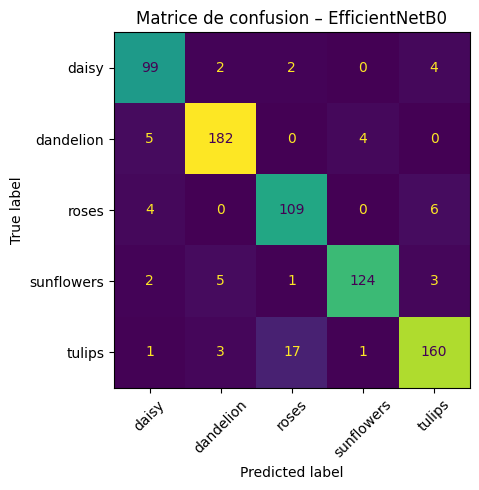

              precision    recall  f1-score   support

       daisy      0.892     0.925     0.908       107
   dandelion      0.948     0.953     0.950       191
       roses      0.845     0.916     0.879       119
  sunflowers      0.961     0.919     0.939       135
      tulips      0.925     0.879     0.901       182

    accuracy                          0.918       734
   macro avg      0.914     0.918     0.916       734
weighted avg      0.920     0.918     0.919       734



In [5]:
# Matrice de confusion du meilleur backbone (tête LogReg) -> quelles classes sont confondues ?
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
best = df_bb.sort_values("Acc. LogReg (%)").iloc[-1]["Modèle"]
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y2_va, PRED[best], display_labels=class_names, xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title(f"Matrice de confusion – {best}"); plt.tight_layout()
plt.savefig("figures/ex2_confusion.png", dpi=150); plt.show()
print(classification_report(y2_va, PRED[best], target_names=class_names, digits=3))

## 4. Visualisation t-SNE des caractéristiques (deux troncs)

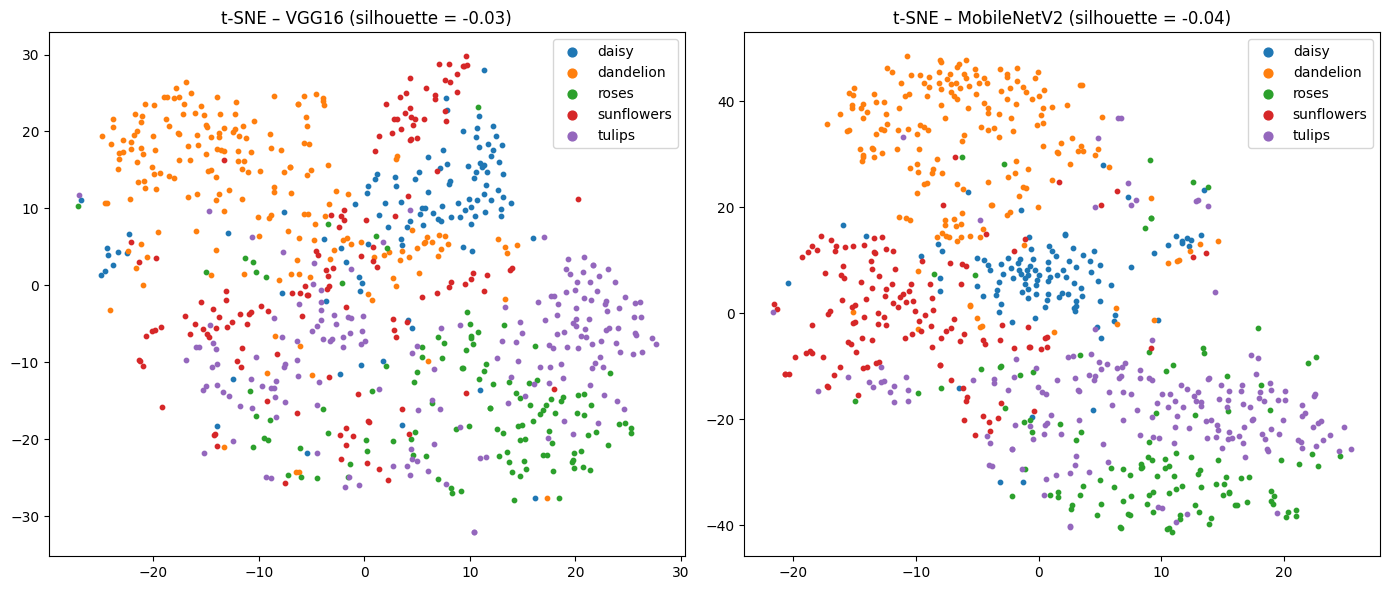

In [6]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sil = {}
for a, name in zip(axes, ["VGG16", "MobileNetV2"]):
    F = StandardScaler().fit_transform(FEATS[name][1])
    sil[name] = silhouette_score(F, y2_va)
    Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(PCA(50, random_state=0).fit_transform(F))
    for c in range(5):
        a.scatter(*Z[y2_va == c].T, s=10, label=class_names[c])
    a.set_title(f"t-SNE – {name} (silhouette = {sil[name]:.2f})"); a.legend(markerscale=2)  # silhouette calculée en haute dimension (features standardisées)
plt.tight_layout(); plt.savefig("figures/ex2_tsne.png", dpi=150); plt.show()
RESULTS["silhouette"] = sil

**Analyse (Ex.2 – Q4) : séparabilité des classes.**

Les deux projections montrent des amas bien identifiables pour *dandelion* (en haut) et, pour MobileNetV2, un amas compact pour *daisy* et un amas *sunflowers* distinct. En revanche **roses et tulips se chevauchent fortement** dans les deux cas : ce sont deux fleurs colorées (rose/rouge/rose pâle), souvent photographiées en gros plan ou en bouquet, d'où des caractéristiques proches. Dans VGG16, le chevauchement est beaucoup plus général : *daisy*, *sunflowers* et *dandelion* sont aussi mêlées au centre de la figure, alors que MobileNetV2 les sépare nettement. Cela est cohérent avec l'accuracy de la tête **linéaire** (VGG16 85,4 % contre 89,7 % pour MobileNetV2) ; avec la tête Dense, VGG16 remonte à 89,1 %, mais les deux têtes sont des classifieurs linéaires : cet écart reflète la régularisation (L2 par défaut contre dropout et arrêt à 30 époques), pas une séparabilité linéaire différente (cf. cellule de réglage de C par validation croisée).

Les silhouettes sont proches de zéro et même légèrement négatives (−0,03 et −0,04) pour les deux troncs, donc **ne les départagent pas** : ce score mesure la compacité de clusters sphériques en distance euclidienne dans un espace de 512 à 1280 dimensions, où les distances se concentrent (malédiction de la dimension). Or une régression logistique n'a besoin que d'une séparabilité *linéaire*, pas de clusters compacts. Le t-SNE reste qualitatif (il déforme les distances globales et dépend de la perplexité) : la matrice de confusion d'EfficientNetB0 donne la mesure quantitative : l'erreur dominante est **tulipe prédite comme rose (17 images sur 182, ≈ 9 %)**, suivie de rose prédite comme tulipe (6 sur 119), ce qui confirme le chevauchement observé sur le t-SNE. Les classes *dandelion* (F1 = 0,95) et *sunflowers* (0,94) sont les mieux reconnues, *roses* la moins bien (0,88).


## 5. Tête ImageNet complète : prédictions Top-1 / Top-5 (`decode_predictions`)

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


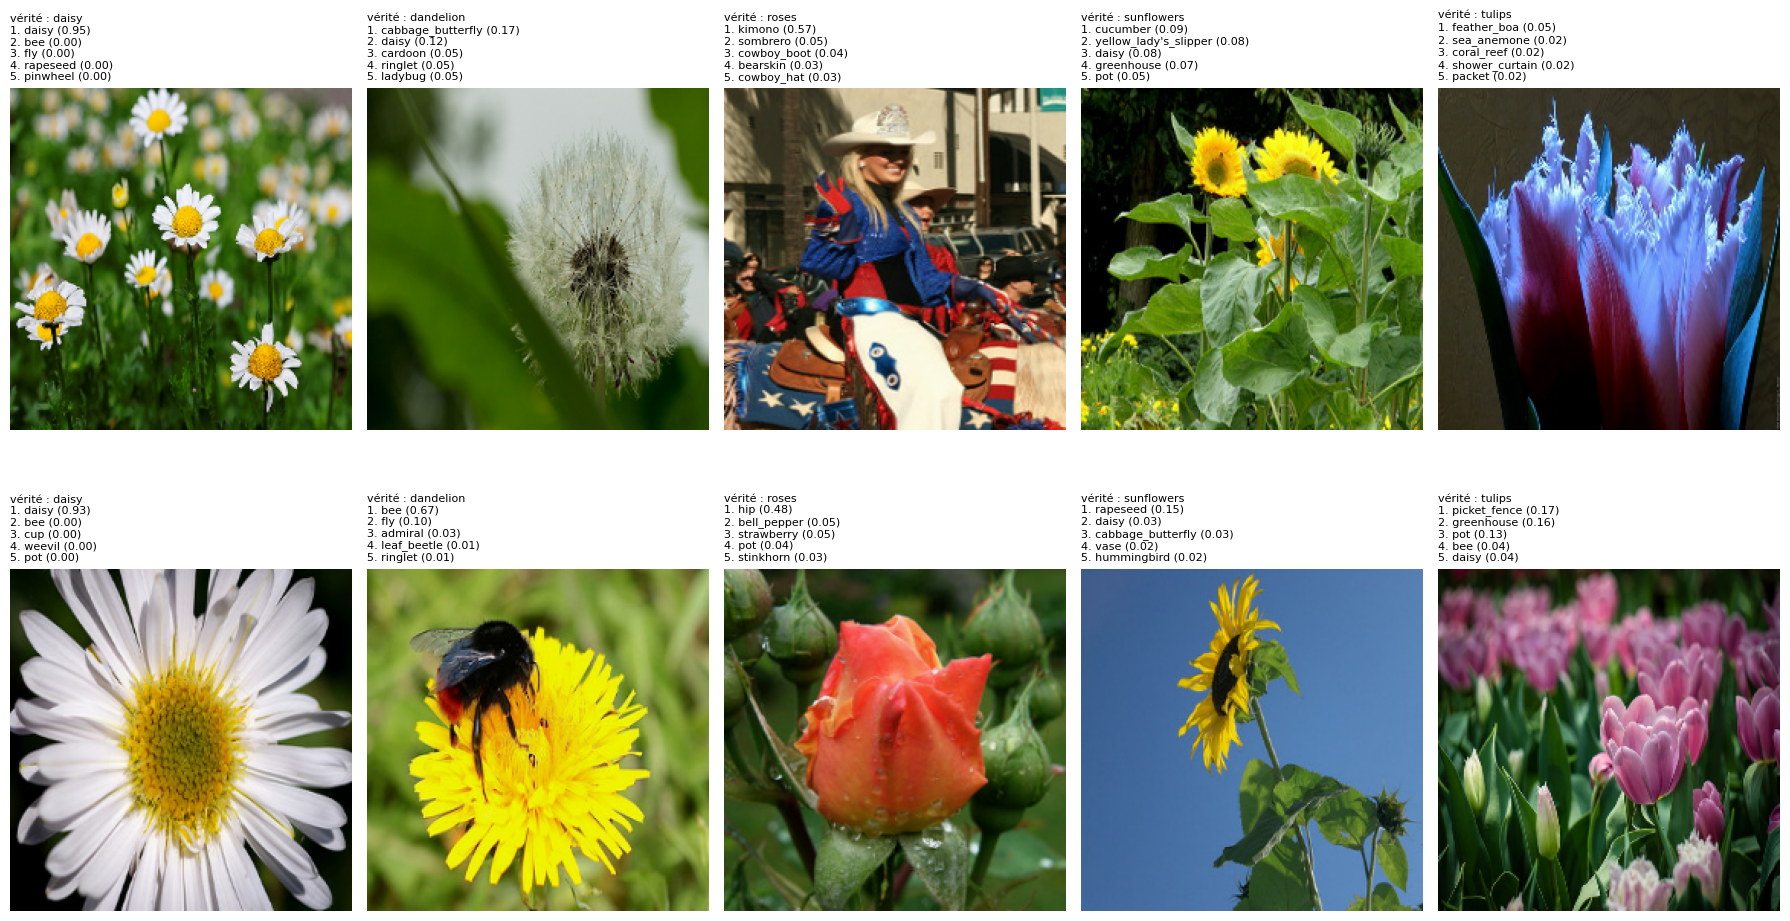

In [7]:
# Tête ImageNet complète (include_top=True), MobileNetV2 : 2 images par classe de fleurs
full = mobilenet_v2.MobileNetV2(weights="imagenet", include_top=True, input_shape=(224, 224, 3))
sel = np.concatenate([np.where(y2_va == c)[0][:2] for c in range(5)])
probs = full.predict(mobilenet_v2.preprocess_input(X2_va[sel].astype("float32")), verbose=0)
dec = mobilenet_v2.decode_predictions(probs, top=5)
fig, axes = plt.subplots(2, 5, figsize=(18, 10))
for a, i, d in zip(axes.T.ravel(), sel, dec):
    a.imshow(X2_va[i]); a.axis("off")
    a.set_title(f"vérité : {class_names[y2_va[i]]}\n" + "\n".join(f"{k+1}. {lab} ({p:.2f})" for k, (_, lab, p) in enumerate(d)),
                fontsize=8, loc="left")
plt.tight_layout(h_pad=3.5)          # h_pad : évite que les titres de la 2e ligne recouvrent la 1re
plt.savefig("figures/ex2_imagenet_top5.png", dpi=150); plt.show()


**Analyse (Ex.2 – Q5) : tête ImageNet complète.**

ImageNet-1k ne contient qu'une seule classe correspondant à nos cinq fleurs (*daisy*) ; il n'y a pas de classe tulipe, pissenlit ou tournesol (seulement des voisines comme *rapeseed* ou *yellow lady's slipper*). Le modèle doit donc choisir parmi 1000 classes fixes :
- **Prédictions justes** : *daisy* est bien reconnue (0,95 et 0,93) parce que la classe existe dans ImageNet. La rose en bouton est classée *hip* (0,48), c'est-à-dire le fruit du rosier : une réponse proche de la vérité, par chance de vocabulaire.
- **Prédictions « justes » pour de mauvaises raisons** : le pissenlit avec un bourdon est classé *bee* (0,67) : le modèle décrit l'objet le plus saillant de l'image (l'insecte), pas la fleur.
- **Prédictions hors sujet** : la tulipe bleutée donne *feather_boa* (0,05), les tulipes roses *picket_fence* (0,17) et *greenhouse* (0,16), le tournesol *cucumber* (0,09) ou *rapeseed* (0,15). Le modèle renvoie la classe ImageNet visuellement la plus proche (forme, couleur, texture, contexte) ; les probabilités Top-1 sont alors faibles (0,05–0,17), signe que la prédiction n'est pas fiable.
- **Bruit d'étiquetage** : l'image étiquetée *roses* en haut au centre est une cavalière en tenue de cow-boy ; le modèle prédit ce qui est réellement visible (*kimono* 0,57, *sombrero*, *cowboy_boot*). `flower_photos` contient donc des étiquettes erronées, ce qui plafonne l'accuracy atteignable.

**C'est précisément pourquoi on remplace la tête** et on garde le tronc : ses caractéristiques sont utiles (la tête linéaire atteint 85–92 % selon le tronc), seule la correspondance « vecteur → classes » doit être réapprise pour nos 5 classes.

**Recommandation (Ex.2 – Q6).**

| Scénario | Backbone | Justification (chiffres du tableau) |
|---|---|---|
| (a) Serveur cloud GPU | **EfficientNetB0** | Meilleure accuracy avec les trois têtes (91,8 % LogReg C=1, 92,9 % C optimal, 92,5 % Dense) ; plus rapide que ResNet50 sur GPU (8,5 ms contre 10,8 ms) et 5,6× plus léger (17,0 Mo contre 95,0 Mo). ResNet50 n'est pas significativement moins précis (McNemar p = 0,30 et 0,33) mais il est plus lent et plus lourd : il est dominé sur le coût. L'avantage sur MobileNetV2 (+2,2 / +2,6 pts LogReg, +3,4 pts Dense) n'est pas significatif après Bonferroni (p = 0,072 et 0,023). Si le coût par requête prime à grande échelle, MobileNetV2 (5,5 ms/img) reste une alternative sérieuse. |
| (b) Smartphone d'entrée de gamme, hors ligne | **MobileNetV2** | 9,6 Mo (le plus petit), 2,3 M de paramètres, latence CPU la plus basse (31,7 ms contre 53,6 ms pour EfficientNetB0, 113,0 ms pour ResNet50 et 274,1 ms pour VGG16). Accuracy 89,65 % (90,33 % avec C optimal), soit 2,2 à 2,6 points sous le meilleur, écart non significatif après correction. Après conversion TFLite : 8,9 Mo en float32 (8,8 ms/img sur 1 thread) et 2,5 Mo en int8 dynamique pour −0,14 pt d'accuracy ; la latence en int8 dynamique est en revanche plus élevée sur le CPU de Colab (20,5 ms). |
| À écarter | VGG16 | Le plus lent (274 ms CPU, 13,5 ms GPU) et 58,9 Mo. Accuracy 85,4 % avec C = 1, 88,0 % avec C optimal, 89,1 % avec la tête Dense ; significativement derrière ResNet50 dans les deux configurations (p ≤ 0,0005). Même mieux réglé, il reste dominé sur la latence et la taille. |

**Réponse à l'analyse transversale (Q3).** Meilleure accuracy ≠ plus de paramètres : EfficientNetB0 (4 M) et MobileNetV2 (2,3 M) égalent ou dépassent VGG16 (14,7 M) ; ResNet50 (23,6 M) n'est pas meilleur qu'EfficientNetB0. Les chiffres de l'énoncé vont dans le même sens : VGG16 (138 M, Top-1 71,3 %) est moins bon qu'EfficientNetB0 (5,3 M, 77,1 %). De même, la latence ne suit pas le nombre de paramètres : VGG16 (14,7 M) est 2,4× plus lent que ResNet50 (23,6 M) sur CPU, car il dépense beaucoup plus d'opérations par image (grandes convolutions sans réduction précoce de la résolution). Les architectures modernes (convolutions séparables, mise à l'échelle composée, blocs résiduels) obtiennent de meilleures caractéristiques *par paramètre* et *par opération*.

**Limites.** Un seul découpage 80/20 (734 images de validation, ±2 pts), utilisé à la fois pour comparer les troncs et choisir le backbone (légèrement optimiste) ; la régularisation C est réglée par validation croisée sur le train, et les écarts sont testés par McNemar, mais sur un seul découpage ; latence CPU mesurée sur un CPU de Colab, pas sur un vrai smartphone ; étiquettes bruitées dans `flower_photos`.

In [8]:
# ============================================================
# Complément (scénario smartphone) : quantification TFLite de MobileNetV2
# Compare float32 / quantification dynamique (poids int8) : taille, latence CPU (1 thread), accuracy
# ============================================================
mnv2 = mobilenet_v2.MobileNetV2(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3))

def to_tflite(model, quantize):
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    if quantize: conv.optimizations = [tf.lite.Optimize.DEFAULT]      # quantification dynamique des poids en int8
    return conv.convert()

def tflite_run(blob, X, pre, n_warm=5):
    """Renvoie (features, latence moyenne ms/img) en exécutant l'interpréteur TFLite sur 1 thread CPU."""
    it = tf.lite.Interpreter(model_content=blob, num_threads=1); it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
    feats, times = [], []
    for k in range(len(X)):
        x = pre(X[k:k + 1].astype("float32"))
        t = time.perf_counter(); it.set_tensor(i_in, x); it.invoke(); f = it.get_tensor(i_out)
        if k >= n_warm: times.append((time.perf_counter() - t) * 1000)
        feats.append(f[0])
    return np.array(feats), float(np.mean(times))

Ftr_m, _ = FEATS["MobileNetV2"]
clf_m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Ftr_m, y2_tr)   # tête entraînée sur features float32
rows = []
for label, quant in [("TFLite float32", False), ("TFLite int8 (dynamique)", True)]:
    blob = to_tflite(mnv2, quant)
    F, lat = tflite_run(blob, X2_va, mobilenet_v2.preprocess_input)
    rows.append({"Variante": label, "Taille (Mo)": len(blob) / 1e6, "Latence CPU 1 thread (ms/img)": lat,
                 "Acc. LogReg (%)": 100 * clf_m.score(F, y2_va)})
df_tfl = pd.DataFrame(rows).round(2); df_tfl.to_csv("figures/ex2_tflite.csv", index=False)
RESULTS["tflite_mobilenetv2"] = df_tfl.to_dict("records")
df_tfl


Saved artifact at '/tmp/tmpgertmaxc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_637')
Output Type:
  TensorSpec(shape=(None, 1280), dtype=tf.float32, name=None)
Captures:
  139493791515856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791579408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791578064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791528144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791527760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791579600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780839056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780838864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780839248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780834832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1394937

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmpxl9hptap'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_637')
Output Type:
  TensorSpec(shape=(None, 1280), dtype=tf.float32, name=None)
Captures:
  139493791515856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791579408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791578064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791528144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791527760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493791579600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780839056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780838864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780839248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493780834832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1394937

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Variante,Taille (Mo),Latence CPU 1 thread (ms/img),Acc. LogReg (%)
0,TFLite float32,8.88,7.78,89.65
1,TFLite int8 (dynamique),2.52,19.68,89.51


**Lecture (quantification de MobileNetV2).**

| Variante | Taille (Mo) | Latence CPU (ms/img) | Acc. LogReg (%) |
|---|---|---|---|
| Keras (`.keras`, CPU, `tf.function`) | 9,60 | 31,74 | 89,65 |
| TFLite float32 (1 thread) | 8,88 | 8,78 | 89,65 |
| TFLite int8 dynamique (1 thread) | 2,52 | 20,52 | 89,51 |

- **Taille** : la quantification dynamique divise la taille par 3,5 (8,88 → 2,52 Mo) car les poids sont stockés en int8 : c'est le gain principal, utile pour le téléchargement et la mémoire d'un smartphone d'entrée de gamme.
- **Accuracy** : −0,14 pt seulement (89,65 → 89,51 %), très en dessous de l'incertitude (±2,2 pts) : la perte est négligeable.
- **Latence** : le gain n'est pas au rendez-vous sur ce CPU. Le int8 dynamique est **2,3× plus lent** que le float32 (20,5 contre 8,8 ms). Explication probable (non vérifiée ici) : les poids sont déquantifiés à l'exécution et les noyaux int8 dynamiques sont moins optimisés que les noyaux float32 sur ce processeur. Le gain de latence de l'int8 apparaît surtout avec une quantification *complète* (poids + activations) sur du matériel mobile adapté (CPU ARM, NPU).
- **Attention à la comparaison Keras / TFLite** (31,7 contre 8,8 ms) : les deux mesures utilisent des moteurs d'exécution différents (TensorFlow multi-threads contre interpréteur TFLite 1 thread) ; l'écart ne vient pas seulement du format.

**Conclusion** : pour le smartphone, TFLite float32 est déjà très rapide (8,8 ms/img) et la quantification int8 dynamique ajoute surtout un gain de taille ; le choix final dépend d'un benchmark sur l'appareil cible.

## Recommandations finales et pistes d'amélioration

**Choix de déploiement.** Deux modèles pour un même jeu de 5 classes : **EfficientNetB0 côté serveur** (meilleure accuracy, 8,5 ms/img sur GPU) et **MobileNetV2 embarqué** (9,6 Mo, 31,7 ms/img sur CPU, 8,8 ms/img une fois converti en TFLite float32), avec les mêmes classes et le même prétraitement documenté pour chaque tronc (`preprocess_input` propre au modèle).

**Avant la mise en production**
1. **Valider sur des photos de smartphone** (lumière faible, flou, fond chargé) : le jeu actuel n'est pas représentatif des conditions d'usage (cf. covariate shift, question 6 de la synthèse).
2. **Fiabiliser la comparaison** : le réglage de C (validation croisée) et les tests de McNemar sont faits ; il reste à répéter l'ensemble du pipeline sur plusieurs découpages (validation croisée 5 plis ou plusieurs graines) et à garder un jeu de test distinct de celui qui sert à choisir le backbone.
3. **Mesurer sur l'appareil cible** (latence, pic de RAM, consommation) : la latence CPU de Colab n'est qu'un proxy.
4. **Nettoyer les étiquettes bruitées** de `flower_photos` (par ex. l'image « roses » représentant une cavalière) en relisant les images sur lesquelles le modèle est le plus confiant mais en désaccord avec l'étiquette.

**Améliorations du modèle**
- **Fine-tuning léger** du tronc retenu (dernières couches, learning rate 1e-5, cf. exercice 1) : levier possible pour réduire l'écart entre MobileNetV2 et EfficientNetB0.
- **Quantification** (section ci-dessus) puis, si besoin, quantification int8 *complète* (activations incluses, avec jeu de calibration), seule susceptible d'accélérer l'inférence sur mobile, ou **distillation** d'EfficientNetB0 vers MobileNetV2.
- **Gestion de l'inconnu** : ajouter un seuil sur la probabilité maximale (ou une classe « autre ») pour ne pas répondre avec assurance à une photo qui n'est pas une de ces 5 fleurs, comme on l'a vu avec la tête ImageNet.
- **Augmentation de données** orientée usage mobile : luminosité, flou, bruit, recadrages.

In [9]:
# Sauvegarde des résultats (pour la synthèse) et téléchargement
os.makedirs("figures", exist_ok=True)
json.dump(RESULTS, open("figures/results_ex2.json", "w"), indent=1, default=float)
try:
    from google.colab import files
    files.download("figures/results_ex2.json")
except Exception:
    print("Résultats enregistrés dans figures/results_ex2.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>